# Single Stock Risk Report

A parameterized report for **one ticker over one date window**, built from the cleaned table `ohlc_hw_cleaned`
(created by `01_data_cleaning.ipynb`). Run it directly, or let `03_run_all_stocks.py` execute it with papermill.

Conventions used in every number below:

* Prices: **adjusted close** (splits and dividends included).
* Daily returns: **log returns** `ln(P_t / P_{t-1})`.
* All values are kept as fractions in the calculations; percentages are applied only when displaying.
* Undefined values (too little history, zero volatility) are shown as **N/A**, never as 0.

In [1]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # Local working copy of the course database

In [2]:
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scrapbook as sb
from IPython.display import display
from matplotlib.ticker import PercentFormatter

%matplotlib inline

TRADING_DAYS_PER_YEAR = 252
VOLATILITY_WINDOW = 20
MOVING_AVERAGE_WINDOW = 50
RISK_FREE_RATE = 0.02

# One colour scheme for the whole report
COLORS = {"high_vol": "#C62828", "low_vol": "#2E7D32", "warm_up": "#9E9E9E", "moving_average": "#1F3A93",
          "volatility": "#6A1B9A", "drawdown": "#D32F2F", "reference_line": "#333333"}
plt.style.use("seaborn-v0_8-whitegrid")

## Data loading and input validation

In [3]:
def validate_inputs(ticker: str, start_date: str, end_date: str, db_path: str) -> Path:
    '''Check the parameters before touching the data; return the resolved database path.'''
    database = Path(db_path).expanduser().resolve()
    if not database.is_file():
        raise FileNotFoundError(f"Database not found: {database}")
    if not isinstance(ticker, str) or not ticker.strip():
        raise ValueError("ticker must be a non-empty string")
    start, end = pd.Timestamp(start_date), pd.Timestamp(end_date)    # raises if not a valid date
    if start > end:
        raise ValueError(f"start_date {start_date} is after end_date {end_date}")
    return database


def load_prices(database: Path, ticker: str, start_date: str, end_date: str) -> pd.DataFrame:
    '''Load the cleaned daily bars for one ticker and date window, indexed by date.'''
    query = '''
        SELECT ts, open, high, low, close, adj_close, volume,
               return_outlier, adj_close_repair, price_interpolated, zero_volume
        FROM ohlc_hw_cleaned
        WHERE ticker = ? AND ts >= ? AND ts <= ?
        ORDER BY ts
    '''
    with closing(sqlite3.connect(database.as_uri() + "?mode=ro", uri=True)) as conn:
        prices = pd.read_sql_query(query, conn, params=(ticker, start_date, end_date),
                                   parse_dates=["ts"], index_col="ts")
    return prices


database = validate_inputs(ticker, start_date, end_date, db_path)
df = load_prices(database, ticker, start_date, end_date)

if len(df) < 2:
    raise ValueError(f"{ticker}: only {len(df)} price(s) between {start_date} and {end_date}; "
                     "at least 2 are needed for a single return. Check the ticker and the dates.")

first_obs, last_obs = df.index.min().strftime("%Y-%m-%d"), df.index.max().strftime("%Y-%m-%d")
print(f"{ticker} from {start_date} to {end_date}: {len(df)} trading days")
print(f"Actual observations: {first_obs} to {last_obs}")

AAPL from 2024-01-01 to 2024-12-31: 202 trading days
Actual observations: 2024-01-02 to 2024-10-18


In [4]:
# Coverage disclosure: the requested window may be wider than the data we actually have
# (a gap of a few days is just a weekend or holiday, so only gaps longer than a week are reported)
coverage_notes = []
if (df.index.min() - pd.Timestamp(start_date)).days > 7:
    coverage_notes.append(f"data starts on {first_obs}, well after the requested start {start_date}")
if (pd.Timestamp(end_date) - df.index.max()).days > 7:
    coverage_notes.append(f"data ends on {last_obs}, before the requested end {end_date} "
                          "(no prices are extrapolated past the last observation)")
if len(df) < VOLATILITY_WINDOW + 1:
    coverage_notes.append(f"only {len(df)} prices: a {VOLATILITY_WINDOW}-day volatility needs at least "
                          f"{VOLATILITY_WINDOW + 1} prices, so rolling volatility is N/A")
if len(df) < MOVING_AVERAGE_WINDOW:
    coverage_notes.append(f"only {len(df)} prices: the {MOVING_AVERAGE_WINDOW}-day moving average needs "
                          f"{MOVING_AVERAGE_WINDOW} prices and is not shown")

print("Coverage notes:" if coverage_notes else "Coverage: full requested window.")
for note in coverage_notes:
    print(" -", note)

display(df.head())
display(df.tail())

Coverage notes:
 - data ends on 2024-10-18, before the requested end 2024-12-31 (no prices are extrapolated past the last observation)


,open,high,low,close,adj_close,volume,return_outlier,adj_close_repair,price_interpolated,zero_volume
ts,,,,,,,,,,
2024-01-02,187.15,188.44,183.89,185.64,184.94,82488674,0,,0,0
2024-01-03,184.22,185.88,183.43,184.25,183.55,58414460,0,,0,0
2024-01-04,182.15,183.09,180.88,181.91,181.22,71983570,0,,0,0
2024-01-05,181.99,182.76,180.17,181.18,180.50,62379661,0,,0,0
2024-01-08,182.09,185.60,181.50,185.56,184.86,59144470,0,,0,0


,open,high,low,close,adj_close,volume,return_outlier,adj_close_repair,price_interpolated,zero_volume
ts,,,,,,,,,,
2024-10-14,228.70,231.73,228.60,231.30,231.30,39882100,0,,0,0
2024-10-15,233.61,237.49,232.37,233.85,233.85,64751400,0,,0,0
2024-10-16,231.60,232.12,229.84,231.78,231.78,34082240,0,,0,0
2024-10-17,233.43,233.85,230.52,232.15,232.15,32993810,0,,0,0
2024-10-18,236.18,236.18,234.01,235.00,235.00,45441281,0,,0,0


In [5]:
# Data-quality context carried over from the cleaning step (flags, not errors)
quality_context = pd.Series({
    "3-sigma return review flags": int(df["return_outlier"].sum()),
    "adj_close rebuilt from reference factor": int((df["adj_close_repair"] != "").sum()),
    "interpolated print errors": int(df["price_interpolated"].sum()),
    "zero-volume days": int(df["zero_volume"].sum()),
}, name="rows in this window")
display(quality_context.to_frame())

,rows in this window
3-sigma return review flags,0
adj_close rebuilt from reference factor,18
interpolated print errors,0
zero-volume days,0


## Risk metrics

In [6]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    '''Calculate daily log returns.

    r_t = ln(P_t / P_{t-1}). The first value is NaN because there is no previous price.
    Prices must be sorted by date, finite and positive.
    '''
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    '''Calculate annualized rolling volatility.

    Sample standard deviation (ddof=1) of the last `window` daily log returns, times sqrt(252).
    The first `window` values are NaN (warm-up); they are left as NaN, never filled with 0.
    '''
    return returns.rolling(window).std() * np.sqrt(TRADING_DAYS_PER_YEAR)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    '''Return per-date drawdown from the running price peak.

    drawdown_t = (P_t - max(P_0..P_t)) / max(P_0..P_t), always <= 0. The series can recover;
    the maximum drawdown of the period is drawdown.min().
    '''
    running_peak = prices.cummax()
    return (prices - running_peak) / running_peak


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    '''Calculate annualized Sharpe ratio (course approximation).

    (mean_daily_return * 252 - risk_free_rate) / (std_daily_return * sqrt(252)).
    Returns NaN when there are fewer than 2 returns or the volatility is zero/undefined.
    '''
    observed = returns.dropna()
    sigma = observed.std()
    if len(observed) < 2 or not np.isfinite(sigma) or np.isclose(sigma, 0):
        return np.nan
    return (observed.mean() * TRADING_DAYS_PER_YEAR - risk_free_rate) / (sigma * np.sqrt(TRADING_DAYS_PER_YEAR))

In [7]:
# Quick checks of the functions on tiny hand-computed examples
example_prices = pd.Series([100.0, 110.0, 99.0, 105.0])
assert np.isclose(calculate_returns(example_prices).iloc[1], np.log(1.1))
np.testing.assert_allclose(calculate_max_drawdown(example_prices), [0.0, 0.0, -0.1, 105 / 110 - 1])
assert np.isnan(calculate_sharpe_ratio(pd.Series([0.01, 0.01, 0.01])))   # zero volatility -> N/A
example_volatility = calculate_volatility(calculate_returns(pd.Series(100.0 + np.arange(25))), window=20)
assert example_volatility.iloc[:20].isna().all() and example_volatility.iloc[20:].notna().all()  # 21 prices needed
print("Function checks passed.")

Function checks passed.


In [8]:
df["log_return"] = calculate_returns(df["adj_close"])
df["volatility"] = calculate_volatility(df["log_return"], window=VOLATILITY_WINDOW)
df["drawdown"] = calculate_max_drawdown(df["adj_close"])
df["ma_50"] = df["adj_close"].rolling(MOVING_AVERAGE_WINDOW).mean()     # NaN until 50 prices exist

log_returns = df["log_return"].dropna()
n_returns = len(log_returns)
mean_volatility = df["volatility"].mean()          # mean of the rolling estimates (NaN if none)
sharpe_ratio = calculate_sharpe_ratio(log_returns, RISK_FREE_RATE)
max_drawdown = df["drawdown"].min()
max_drawdown_date = df["drawdown"].idxmin()

display(df[["adj_close", "log_return", "volatility", "drawdown", "ma_50"]].tail())
print(f"Sharpe ratio: {sharpe_ratio:.2f}" if pd.notna(sharpe_ratio) else "Sharpe ratio: N/A")
print(f"Maximum drawdown: {max_drawdown:.2%} on {max_drawdown_date:%Y-%m-%d}")

,adj_close,log_return,volatility,drawdown,ma_50
ts,,,,,
2024-10-14,231.30,0.016346,0.242503,-0.013856,223.6422
2024-10-15,233.85,0.010964,0.243942,-0.002984,224.1386
2024-10-16,231.78,-0.008891,0.241973,-0.011810,224.6344
2024-10-17,232.15,0.001595,0.206097,-0.010232,225.0858
2024-10-18,235.00,0.012202,0.209521,0.000000,225.5246


Sharpe ratio: 1.19
Maximum drawdown: -15.35% on 2024-04-19


## Visual report

* **Price** line colour uses the report's mean rolling volatility as the threshold: red = above the mean,
  green = at or below, gray = warm-up (no 20-day estimate yet). The colouring is retrospective.
* **Drawdown** uses layered transparent red fills to create the gradient; the black dot marks the maximum drawdown.

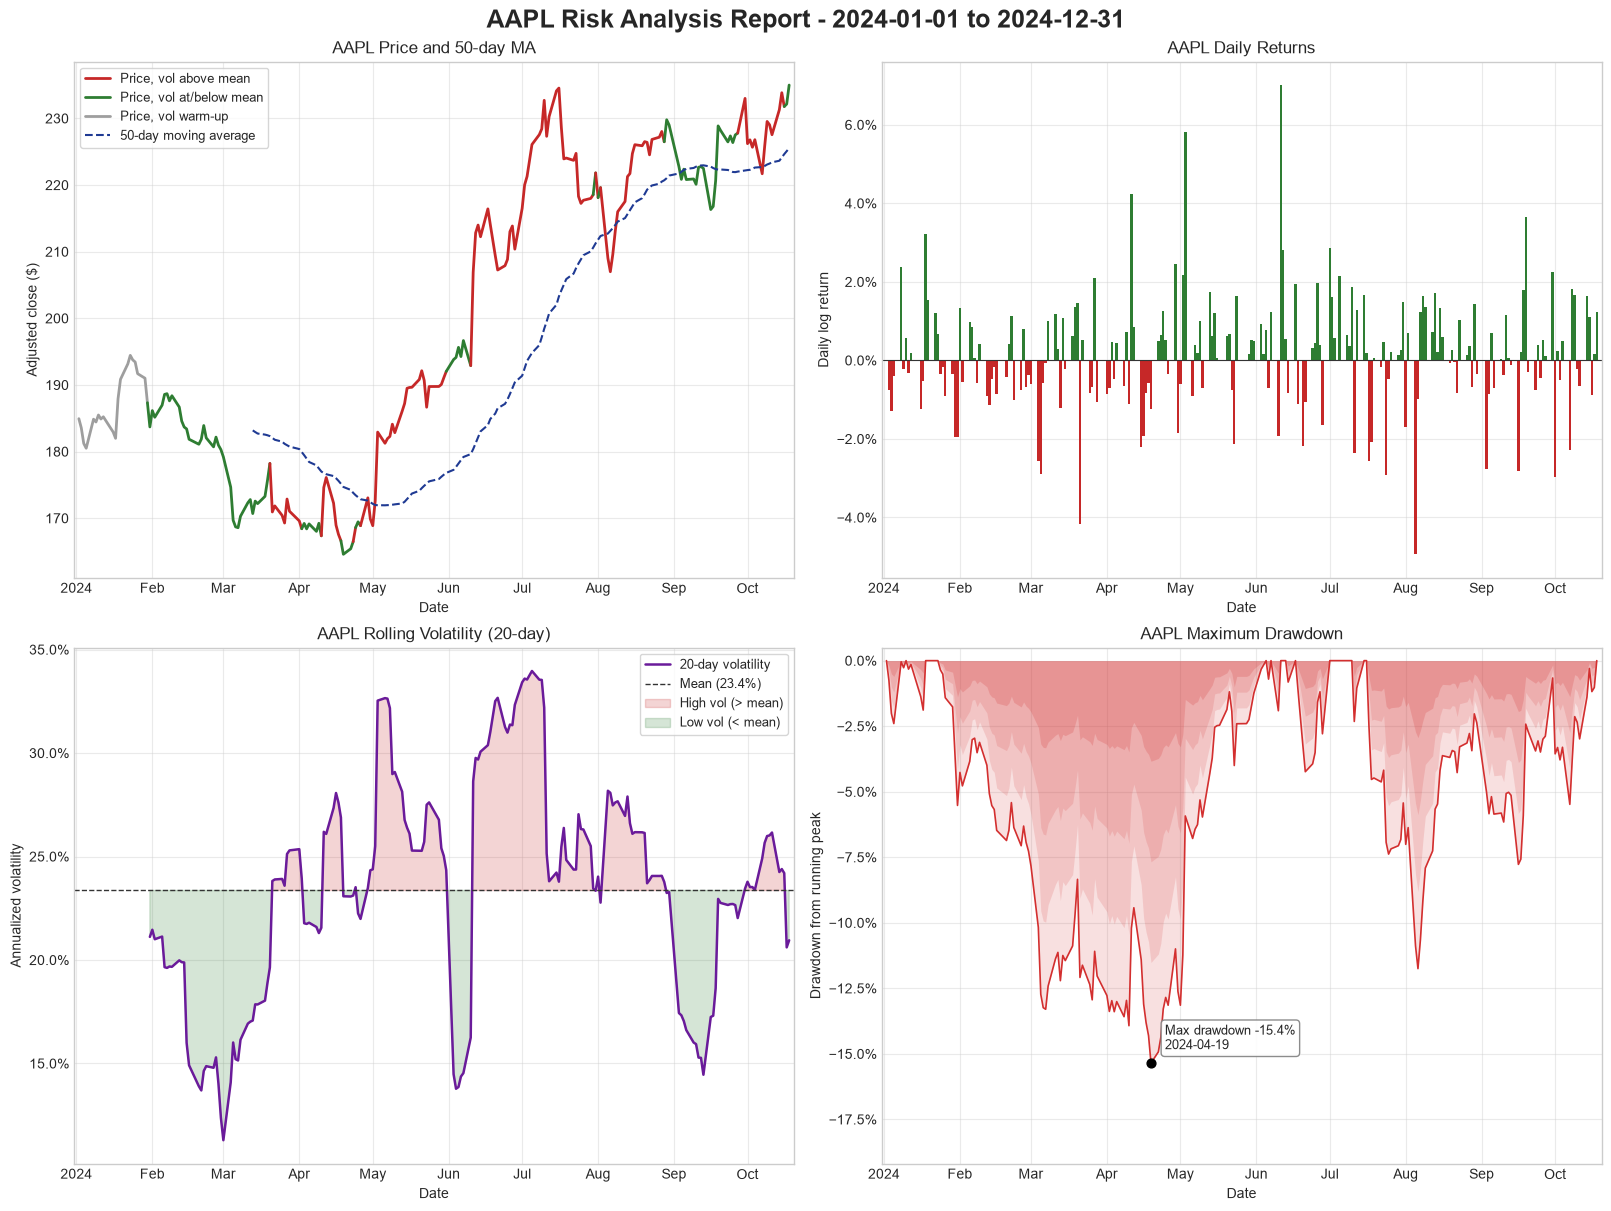

Chart notes:
 - Price: 202 adjusted closes; 50-day MA from 2024-03-13
 - Volatility colouring threshold (mean 20-day vol): 23.36%; 105 days above (red), 77 at/below (green), 20 warm-up days (gray), first estimate 2024-01-31
 - Daily returns: 112 up (green), 89 down (red), 0 unchanged
 - Drawdown: maximum -15.35% on 2024-04-19 (black dot)


In [9]:
def plot_price(ax, df):
    '''Adjusted close coloured by volatility regime, plus the 50-day moving average.'''
    # Colour of the line segment that ENDS on each day, based on that day's rolling volatility
    day_colour = pd.Series([COLORS["warm_up"] if np.isnan(v) else COLORS["high_vol"] if v > mean_volatility
                            else COLORS["low_vol"] for v in df["volatility"]], index=df.index)
    # Draw each run of consecutive days with the same colour as one line; start each run one day
    # earlier so that the runs connect without gaps
    run_number = (day_colour != day_colour.shift()).cumsum()
    for _, run in day_colour.iloc[1:].groupby(run_number.iloc[1:]):
        first = df.index.get_loc(run.index[0]) - 1
        last = df.index.get_loc(run.index[-1])
        ax.plot(df.index[first:last + 1], df["adj_close"].iloc[first:last + 1], color=run.iloc[0], linewidth=2)
    if df["ma_50"].notna().any():
        ax.plot(df.index, df["ma_50"], color=COLORS["moving_average"], linewidth=1.5, linestyle="--",
                label="50-day moving average")
    else:
        ax.text(0.02, 0.04, "50-day MA unavailable: fewer than 50 prices", transform=ax.transAxes, fontsize=9)
    legend_items = [plt.Line2D([], [], color=COLORS["high_vol"], lw=2, label="Price, vol above mean"),
                    plt.Line2D([], [], color=COLORS["low_vol"], lw=2, label="Price, vol at/below mean"),
                    plt.Line2D([], [], color=COLORS["warm_up"], lw=2, label="Price, vol warm-up")]
    if df["ma_50"].notna().any():
        legend_items.append(plt.Line2D([], [], color=COLORS["moving_average"], lw=1.5, ls="--",
                                       label="50-day moving average"))
    ax.legend(handles=legend_items, loc="best", fontsize=9, frameon=True)
    ax.set(title=f"{ticker} Price and 50-day MA", ylabel="Adjusted close ($)")


def plot_returns(ax, df):
    '''Daily log returns as green (positive) / red (negative) bars.'''
    returns = df["log_return"].dropna()
    colours = np.where(returns >= 0, COLORS["low_vol"], COLORS["high_vol"])
    ax.bar(returns.index, returns, color=colours, width=1.0)
    ax.axhline(0, color=COLORS["reference_line"], linewidth=0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set(title=f"{ticker} Daily Returns", ylabel="Daily log return")


def plot_volatility(ax, df):
    '''20-day rolling volatility with its mean and shaded high/low regimes.'''
    vol = df["volatility"]
    if vol.notna().any():
        ax.plot(df.index, vol, color=COLORS["volatility"], linewidth=1.8, label="20-day volatility")
        ax.axhline(mean_volatility, color=COLORS["reference_line"], linestyle="--", linewidth=1,
                   label=f"Mean ({mean_volatility:.1%})")
        ax.fill_between(df.index, vol, mean_volatility, where=vol > mean_volatility, interpolate=True,
                        color=COLORS["high_vol"], alpha=0.2, label="High vol (> mean)")
        ax.fill_between(df.index, vol, mean_volatility, where=vol < mean_volatility, interpolate=True,
                        color=COLORS["low_vol"], alpha=0.2, label="Low vol (< mean)")
        ax.legend(loc="best", fontsize=9, frameon=True)
    else:
        ax.text(0.5, 0.5, "Not enough prices for a 20-day volatility", ha="center", transform=ax.transAxes)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set(title=f"{ticker} Rolling Volatility (20-day)", ylabel="Annualized volatility")


def plot_drawdown(ax, df):
    '''Per-date drawdown as a layered red area, with the maximum drawdown marked.'''
    drawdown = df["drawdown"]
    for fraction, alpha in [(1.0, 0.15), (0.75, 0.15), (0.5, 0.15), (0.25, 0.2)]:
        ax.fill_between(df.index, drawdown * fraction, 0, color=COLORS["drawdown"], alpha=alpha, linewidth=0)
    ax.plot(df.index, drawdown, color=COLORS["drawdown"], linewidth=1.2)
    ax.scatter([max_drawdown_date], [max_drawdown], color="black", zorder=3, s=40)
    ax.annotate(f"Max drawdown {max_drawdown:.1%}\n{max_drawdown_date:%Y-%m-%d}",
                (max_drawdown_date, max_drawdown), xytext=(10, 10), textcoords="offset points", fontsize=9,
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.9))
    ax.set_ylim(min(max_drawdown * 1.25, -0.01), 0.005)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set(title=f"{ticker} Maximum Drawdown", ylabel="Drawdown from running peak")


fig, axes = plt.subplots(2, 2, figsize=(16, 12), layout="constrained")
fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=18, fontweight="bold")
plot_price(axes[0, 0], df)
plot_returns(axes[0, 1], df)
plot_volatility(axes[1, 0], df)
plot_drawdown(axes[1, 1], df)
padding = pd.Timedelta(days=2)
for ax in axes.flat:
    ax.grid(True, alpha=0.4)
    ax.set_xlabel("Date")
    ax.set_xlim(df.index.min() - padding, df.index.max() + padding)   # same date range on all panels
    date_locator = mdates.AutoDateLocator()                             # sensible ticks for any window length
    ax.xaxis.set_major_locator(date_locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(date_locator))
plt.show()

# Text summary of what each panel shows (useful when the notebook is read without images)
vol_days = df["volatility"].dropna()
ma_start = df["ma_50"].first_valid_index()
print("Chart notes:")
print(f" - Price: {len(df)} adjusted closes; 50-day MA "
      + (f"from {ma_start:%Y-%m-%d}" if ma_start is not None else "unavailable (fewer than 50 prices)"))
if len(vol_days):
    print(f" - Volatility colouring threshold (mean 20-day vol): {mean_volatility:.2%}; "
          f"{(vol_days > mean_volatility).sum()} days above (red), {(vol_days <= mean_volatility).sum()} at/below "
          f"(green), {df['volatility'].isna().sum()} warm-up days (gray), first estimate {vol_days.index[0]:%Y-%m-%d}")
else:
    print(" - Volatility: no 20-day estimate available (fewer than 21 prices)")
print(f" - Daily returns: {(log_returns > 0).sum()} up (green), {(log_returns < 0).sum()} down (red), "
      f"{(log_returns == 0).sum()} unchanged")
print(f" - Drawdown: maximum {max_drawdown:.2%} on {max_drawdown_date:%Y-%m-%d} (black dot)")

## Summary statistics

* Total return = `last adj_close / first adj_close - 1`
* Annualized return = `exp(sum(log returns) * 252 / n) - 1` (compounded)
* Annualized volatility = `std(log returns) * sqrt(252)` for the whole window (different from the *mean rolling*
  volatility used in the portfolio summary)
* Best/worst day and average up/down day use log returns; positive days = positive returns / **all** non-missing
  returns (zero-return days count in the denominator)

In [10]:
def summary_statistics(df: pd.DataFrame, log_returns: pd.Series) -> pd.Series:
    '''All report metrics as fractions (NaN when undefined).'''
    n = len(log_returns)
    up_days = log_returns[log_returns > 0]
    down_days = log_returns[log_returns < 0]
    return pd.Series({
        "Total Return": df["adj_close"].iloc[-1] / df["adj_close"].iloc[0] - 1,
        "Annualized Return": np.exp(log_returns.sum() * TRADING_DAYS_PER_YEAR / n) - 1 if n > 0 else np.nan,
        "Annualized Volatility": log_returns.std() * np.sqrt(TRADING_DAYS_PER_YEAR) if n > 1 else np.nan,
        "Sharpe Ratio": sharpe_ratio,
        "Maximum Drawdown": max_drawdown,
        "Best Day": log_returns.max() if n > 0 else np.nan,
        "Worst Day": log_returns.min() if n > 0 else np.nan,
        "Positive Days": len(up_days) / n if n > 0 else np.nan,
        "Average Up Day": up_days.mean() if len(up_days) > 0 else np.nan,
        "Average Down Day": down_days.mean() if len(down_days) > 0 else np.nan,
    })


def format_metric(name: str, value: float) -> str:
    '''Display formatting only: N/A for undefined, signed % for returns, plain number for Sharpe.'''
    if pd.isna(value):
        return "N/A"
    if name == "Sharpe Ratio":
        return f"{value:.2f}"
    if name in ("Annualized Volatility", "Positive Days"):
        return f"{value:.2%}"
    return f"{value:+.2%}"


metrics = summary_statistics(df, log_returns)
summary_table = pd.DataFrame({"Metric": metrics.index,
                              "Value": [format_metric(name, value) for name, value in metrics.items()]})

print(f"{ticker} summary: {first_obs} to {last_obs}, {len(df)} prices, {n_returns} log returns\n")
print(f"{'Metric':<24}  {'Value':>8}")
print(f"{'-' * 24}  {'-' * 8}")
for row in summary_table.itertuples():
    print(f"{row.Metric:<24}  {row.Value:>8}")

AAPL summary: 2024-01-02 to 2024-10-18, 202 prices, 201 log returns

Metric                       Value
------------------------  --------
Total Return               +27.07%
Annualized Return          +35.03%
Annualized Volatility       23.61%
Sharpe Ratio                  1.19
Maximum Drawdown           -15.35%
Best Day                    +7.01%
Worst Day                   -4.94%
Positive Days               55.72%
Average Up Day              +1.08%
Average Down Day            -1.09%


## Export results for the portfolio run

The results are saved with scrapbook as one named scrap, `report_results`, so `03_run_all_stocks.py` can
collect them from each executed report.

In [11]:
def as_float_or_none(value):
    '''JSON-friendly number: NaN becomes None (null), so undefined values stay undefined.'''
    return None if pd.isna(value) else float(value)


results = {
    "ticker": ticker,
    "start_date": start_date,
    "end_date": end_date,
    "first_observation": first_obs,
    "last_observation": last_obs,
    "trading_days": int(len(df)),
    "avg_daily_return": as_float_or_none(log_returns.mean()),
    "avg_volatility": as_float_or_none(mean_volatility),
    "max_drawdown": as_float_or_none(max_drawdown),
    "sharpe_ratio": as_float_or_none(sharpe_ratio),
    "total_return": as_float_or_none(metrics["Total Return"]),
    "annualized_return": as_float_or_none(metrics["Annualized Return"]),
    "annualized_volatility": as_float_or_none(metrics["Annualized Volatility"]),
}
# One named scrap holding every result (a JSON object; undefined values are stored as null)
sb.glue("report_results", results)
print("Results saved with scrapbook under the name 'report_results'.")

Results saved with scrapbook under the name 'report_results'.
